# Tune D_LVDC using the first charge cycle

**Context**: This notebook sweeps SEI diffusivities (D_LEDC and D_LVDC) using
only the **first charge cycle** of formation (`include_flag=0`).  The first
charge cycle is where the majority of the VC (LVDC) reaction occurs, making it
the most sensitive window for identifying D_LVDC.

Key differences relative to the full-protocol sweep
(`2026_04_07_clean_dsei_sweep`):

* Uses **`expt2`** (cell 152074, baseline formation repeat 2) for the "base"
  protocol, matching the convention in the clean-sweep notebook.
* Voltage RMSE range starts at **2.0 V** (not 3.2 V) to capture the full
  first-charge voltage profile from the low initial OCV.
* Expansion curves are **smoothed** (`daq_strain_smoothed`) to remove the
  early-time kink artefact before RMSE calculation.
* The result of this notebook is used to **set D_LVDC**; subsequent notebooks
  then fix D_LVDC and tune D_LEDC, densities, and conductivities.

Andrew Weng

In [1]:
import os, sys

if os.path.basename(os.getcwd()) in ('notebooks', 'notebooks_2026'):
    os.chdir('../')
    sys.path.insert(0, 'src/')

from src import cellsim as cellsim

from scipy.interpolate import interp1d

import pickle
import numpy as np
from matplotlib import pyplot as plt
from src import plotter as plotter
from src import ioutils as ioutils 
from src import simutils as simutils

%load_ext autoreload
%matplotlib inline

plotter.initialize(plt)

# Load the experimental data

In [ ]:
# Load the experimental data
expt1, _ = ioutils.fetch_experimental_data(152064, 600)
expt2, _ = ioutils.fetch_experimental_data(152074, 600)
expt3, _ = ioutils.fetch_experimental_data(152071, 600)
expt4, _ = ioutils.fetch_experimental_data(152098, 600)


dt_data_interp = 5.0
t_interp1, i_interp1 = simutils.interpolate_raw_data(expt1['arbin_time'], expt1['arbin_current'], dt_data_interp)
t_interp2, i_interp2 = simutils.interpolate_raw_data(expt2['arbin_time'], expt2['arbin_current'], dt_data_interp)
t_interp3, i_interp3 = simutils.interpolate_raw_data(expt3['arbin_time'], expt3['arbin_current'], dt_data_interp)
t_interp4, i_interp4 = simutils.interpolate_raw_data(expt4['arbin_time'], expt4['arbin_current'], dt_data_interp)

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(np.array(expt1['daq_time'])/3600, expt1['daq_strain'], label='base1')
plt.plot(np.array(expt2['daq_time'])/3600, expt2['daq_strain'], label='base2')
plt.plot(np.array(expt3['daq_time'])/3600, expt3['daq_strain'], label='fast')
plt.plot(np.array(expt4['daq_time'])/3600, expt4['daq_strain'], label='fast+')
plt.xlabel('Time (hr)')
plt.ylabel('Expansion (Strain)')
plt.title('Expansion vs Time')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Define affected regions for each dataset
# Format: (expt, label, t_start, t_end)
kink_regions = [
    (expt1, 'Base 1', 0.5, 0.75),
    (expt2, 'Base 2', 0.5, 0.85),
    (expt3, 'Fast', 0.5, 0.6),
    (expt4, 'Fast+', 0.5, 0.55),
]

# Apply smoothing to each dataset
smoothed_strains = {}
for expt, label, t_start, t_end in kink_regions:
    daq_time = np.array(expt['daq_time'])
    daq_strain = np.array(expt['daq_strain'])
    
    # Convert to hours from zero
    daq_time_hours = (daq_time - daq_time[0]) / 3600.0
    
    # Apply smoothing
    strain_smoothed = ioutils.smooth_kink_region(daq_time_hours, daq_strain, t_start, t_end)
    smoothed_strains[label] = {
        'time_hours': daq_time_hours,
        'original': daq_strain,
        'smoothed': strain_smoothed,
        't_start': t_start,
        't_end': t_end
    }

expt1['daq_strain_smoothed'] = smoothed_strains['Base 1']['smoothed']
expt2['daq_strain_smoothed'] = smoothed_strains['Base 2']['smoothed']
expt3['daq_strain_smoothed'] = smoothed_strains['Fast']['smoothed']
expt4['daq_strain_smoothed'] = smoothed_strains['Fast+']['smoothed']

# Sweep diffusivities (first charge cycle only)

In [ ]:
nn = 55

diff_ec_vec = np.logspace(-20, -16, nn)
diff_vc_vec = np.logspace(-21, -12, nn + 1)

shape = (len(diff_ec_vec), len(diff_vc_vec))
_mat_names = [
    'rmse1_e_mat', 'rmse1_v_mat', 'rmse2_e_mat', 'rmse2_v_mat', 'rmse3_e_mat', 'rmse3_v_mat',
    'qsei1_mat', 'qsei2_mat', 'qsei3_mat', 'qsei1_vc_mat', 'qsei2_vc_mat', 'qsei3_vc_mat',
    'expan1_mat', 'expan2_mat', 'expan3_mat',
    'resistance1_mat', 'resistance2_mat', 'resistance3_mat',
]
for _name in _mat_names:
    globals()[_name] = np.zeros(shape)

count = 1

for i, diff_ec in enumerate(diff_ec_vec):
    for j, diff_vc in enumerate(diff_vc_vec):

        print(f'Running D_EC = {diff_ec:.2e} m2/s and D_VC = {diff_vc:.2e} m2/s ({count} of {nn*(nn+1)})')
        count += 1

        try:
            df_sim1 = simutils.run_sim('base', diff_ec, diff_vc, dt=1, include_flag=0)
            df_sim2 = simutils.run_sim('fast', diff_ec, diff_vc, dt=1, include_flag=0)
            df_sim3 = simutils.run_sim('fast+', diff_ec, diff_vc, dt=1, include_flag=0)
        except:
            print('ERROR')
            continue

        # Extract the qsei values:
        qsei1_mat[i, j] = df_sim1['q_sei'].iloc[-1]
        qsei2_mat[i, j] = df_sim2['q_sei'].iloc[-1]
        qsei3_mat[i, j] = df_sim3['q_sei'].iloc[-1]

        qsei1_vc_mat[i, j] = df_sim1['q_sei2'].iloc[-1]
        qsei2_vc_mat[i, j] = df_sim2['q_sei2'].iloc[-1]
        qsei3_vc_mat[i, j] = df_sim3['q_sei2'].iloc[-1]

        # Extract the expansion values:
        expan1_mat[i, j] = df_sim1['expansion'].iloc[-1]
        expan2_mat[i, j] = df_sim2['expansion'].iloc[-1]
        expan3_mat[i, j] = df_sim3['expansion'].iloc[-1]

        # Extract the resistance values:
        resistance1_mat[i, j] = df_sim1['R_sei'].iloc[-1]
        resistance2_mat[i, j] = df_sim2['R_sei'].iloc[-1]
        resistance3_mat[i, j] = df_sim3['R_sei'].iloc[-1]

        # Beware of experimental vs model data indexing!!
        rmse1_v, _, _ = simutils.calculate_rmse(expt2['arbin_time'], expt2['arbin_voltage'], df_sim1['t'], df_sim1['vt'], ignore_time_range=(0,30*60), y_range=(2.0, 4.2))
        rmse1_e, _, _ = simutils.calculate_rmse(expt2['daq_time'],   expt2['daq_strain_smoothed'], df_sim1['t'], df_sim1['expansion']*1e6, ignore_time_range=(0,30*60))
        rmse2_v, _, _ = simutils.calculate_rmse(expt3['arbin_time'], expt3['arbin_voltage'], df_sim2['t'], df_sim2['vt'], ignore_time_range=(0,30*60), y_range=(2.0, 4.2))
        rmse2_e, _, _ = simutils.calculate_rmse(expt3['daq_time'],   expt3['daq_strain_smoothed'], df_sim2['t'], df_sim2['expansion']*1e6, ignore_time_range=(0,30*60))
        rmse3_v, _, _ = simutils.calculate_rmse(expt4['arbin_time'], expt4['arbin_voltage'], df_sim3['t'], df_sim3['vt'], ignore_time_range=(0,30*60), y_range=(2.0, 4.2))
        rmse3_e, _, _ = simutils.calculate_rmse(expt4['daq_time'],   expt4['daq_strain_smoothed'], df_sim3['t'], df_sim3['expansion']*1e6, ignore_time_range=(0,30*60))

        rmse1_e_mat[i, j] = rmse1_e
        rmse1_v_mat[i, j] = rmse1_v
        rmse2_e_mat[i, j] = rmse2_e
        rmse2_v_mat[i, j] = rmse2_v
        rmse3_e_mat[i, j] = rmse3_e
        rmse3_v_mat[i, j] = rmse3_v

# Replace zeros with np.nan (failed runs)
for _name in _mat_names:
    globals()[_name] = np.where(globals()[_name] == 0, np.nan, globals()[_name])

combined_rmse1 = rmse1_e_mat/np.nanmax(rmse1_e_mat) + rmse1_v_mat/np.nanmax(rmse1_v_mat)
combined_rmse2 = rmse2_e_mat/np.nanmax(rmse2_e_mat) + rmse2_v_mat/np.nanmax(rmse2_v_mat)
combined_rmse3 = rmse3_e_mat/np.nanmax(rmse3_e_mat) + rmse3_v_mat/np.nanmax(rmse3_v_mat)

Rother = 0.0215 - 0.09197987391102377
Rmeas1 = 0.0215 
Rmeas2 = 0.0178 
Rmeas3 = 0.0166 
Q_max  = 2.87
Q_meas = 2.54

# Capacity error
eq1_mat = (qsei1_mat - (Q_max - Q_meas))**2
eq2_mat = (qsei2_mat - (Q_max - Q_meas))**2
eq3_mat = (qsei3_mat - (Q_max - Q_meas))**2

# Resistance error
er1_mat = ((resistance1_mat + Rother) - Rmeas1)**2
er2_mat = ((resistance2_mat + Rother) - Rmeas2)**2
er3_mat = ((resistance3_mat + Rother) - Rmeas3)**2

# Combined capacity and resistance error
ec1_mat = (eq1_mat / np.nanmax(eq1_mat)) + (er1_mat / np.nanmax(er1_mat))
ec2_mat = (eq2_mat / np.nanmax(eq2_mat)) + (er2_mat / np.nanmax(er2_mat))
ec3_mat = (eq3_mat / np.nanmax(eq3_mat)) + (er3_mat / np.nanmax(er3_mat))

In [2]:
%autoreload 2

variables_to_pickle = {
    'rmse1_e_mat': rmse1_e_mat,
    'rmse1_v_mat': rmse1_v_mat,
    'rmse2_e_mat': rmse2_e_mat,
    'rmse2_v_mat': rmse2_v_mat,
    'rmse3_e_mat': rmse3_e_mat,
    'rmse3_v_mat': rmse3_v_mat,
    'qsei1_mat': qsei1_mat,
    'qsei2_mat': qsei2_mat,
    'qsei3_mat': qsei3_mat,
    'qsei1_vc_mat': qsei1_vc_mat,
    'qsei2_vc_mat': qsei2_vc_mat,
    'qsei3_vc_mat': qsei3_vc_mat,
    'expan1_mat': expan1_mat,
    'expan2_mat': expan2_mat,
    'expan3_mat': expan3_mat,
    'resistance1_mat': resistance1_mat,
    'resistance2_mat': resistance2_mat,
    'resistance3_mat': resistance3_mat,
    'combined_rmse1': combined_rmse1,
    'combined_rmse2': combined_rmse2,
    'combined_rmse3': combined_rmse3,
    'eq1_mat': eq1_mat,
    'eq2_mat': eq2_mat,
    'eq3_mat': eq3_mat,
    'er1_mat': er1_mat,
    'er2_mat': er2_mat,
    'er3_mat': er3_mat,
    'ec1_mat': ec1_mat,
    'ec2_mat': ec2_mat,
    'ec3_mat': ec3_mat,
}

with open('notebooks_2026/data/simulation_results_ec_tuning_diff_20260416.pkl', 'wb') as f:
    pickle.dump(variables_to_pickle, f)

NameError: name 'rmse1_e_mat' is not defined

# Visualize results

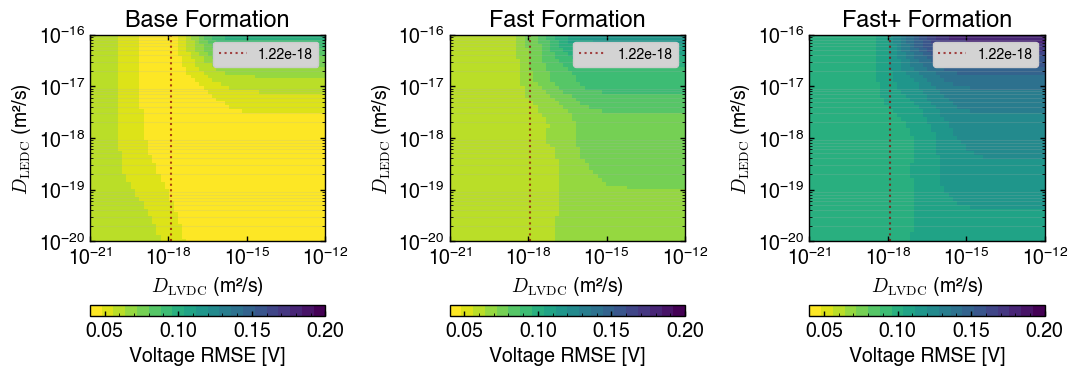

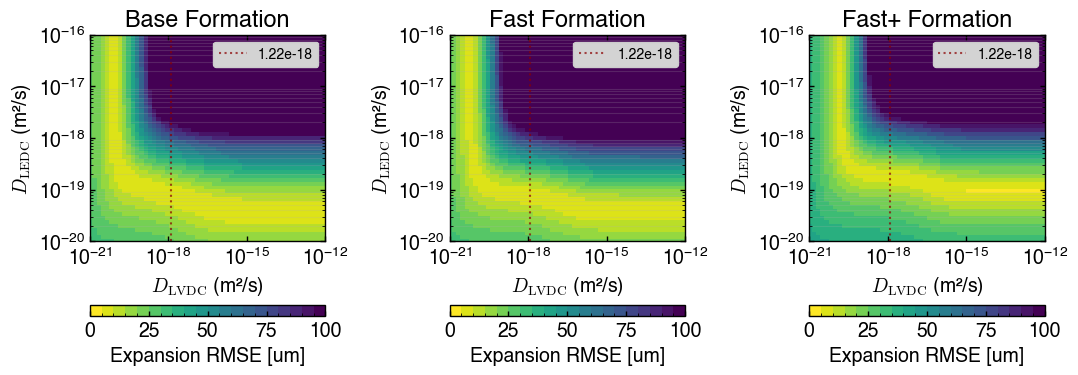

In [15]:
%matplotlib inline
with open('notebooks_2026/data/simulation_results_ec_tuning_diff_20260421.pkl', 'rb') as f:
    sim_results = pickle.load(f)
nn = 55

diff_ec_vec = np.logspace(-20, -16, nn)
diff_vc_vec = np.logspace(-21, -12, nn + 1)

simutils.plot_heatmaps_diff(
    diff_ec_vec, diff_vc_vec,
    sim_results['rmse1_v_mat'], sim_results['rmse2_v_mat'], sim_results['rmse3_v_mat'], 'Voltage RMSE [V]',
    to_annotate=True,
    zmin=0.04, zmax=0.2,
    annotation_orientation='vertical',
    annotation_coord=1.22e-18,
    annotation_line_only=True,
    tosave=True,
    savename=f'outputs/figures/heatmap_diff_rmse_v_form_firstcyc.svg'
    )

simutils.plot_heatmaps_diff(
    diff_ec_vec, diff_vc_vec,
    sim_results['rmse1_e_mat'], sim_results['rmse2_e_mat'], sim_results['rmse3_e_mat'], 'Expansion RMSE [um]',
    to_annotate=True,
    zmin=0, zmax=100,
    annotation_orientation='vertical',
    annotation_coord=1.22e-18,
    annotation_line_only=True,
    tosave=True,
    savename=f'outputs/figures/heatmap_diff_rmse_e_form_firstcyc.svg'
    )